# Lab 2 - Non-Linear Clustering with DBSCAN
## JS07 - Clustering

**Name:** Tiara Febrianie  
**NIM:** 244107020097  

### Objectives
1. Investigate the limitations of centroid-based algorithms (K-Means) on non-linearly separable data.
2. Implement Density-Based Spatial Clustering of Applications with Noise (DBSCAN) using scikit-learn.
3. Understand core concepts of DBSCAN: Core points, Border points, Noise points, epsilon ($\epsilon$), and `min_samples`.
4. Critically evaluate clustering quality on non-linear geometries using:
   - Visual inspection
   - Silhouette Coefficient and its limitations on arbitrary-shaped manifolds
   - Davies-Bouldin Index (DBI)
   - Noise percentage analysis


## Step 0 - Import Libraries
Import required numerical computation, visualization, clustering algorithms, and validation metrics.


In [1]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Set aesthetic styling
sns.set_theme(style='whitegrid')
%matplotlib inline


## Step 1 - Creating a Synthetic Dataset
In this experiment, we generate synthetic data with complex, non-linear geometric structures using `make_moons`.  
The dataset generates two interleaving half-circle / spiral shapes that cannot be separated linearly in two dimensions.


In [2]:
# Generate non-linear moon-shaped synthetic data
X, y = make_moons(n_samples=200, noise=0.05, random_state=0)

print(f"Data shape: {X.shape}")
print(f"First 5 coordinates:\n{X[:5]}")


Data shape: (200, 2)
First 5 coordinates:
[[ 0.81680544  0.5216447 ]
 [ 1.61859642 -0.37982927]
 [-0.02126953  0.27372826]
 [-1.02181041 -0.07543984]
 [ 1.76654633 -0.17069874]]


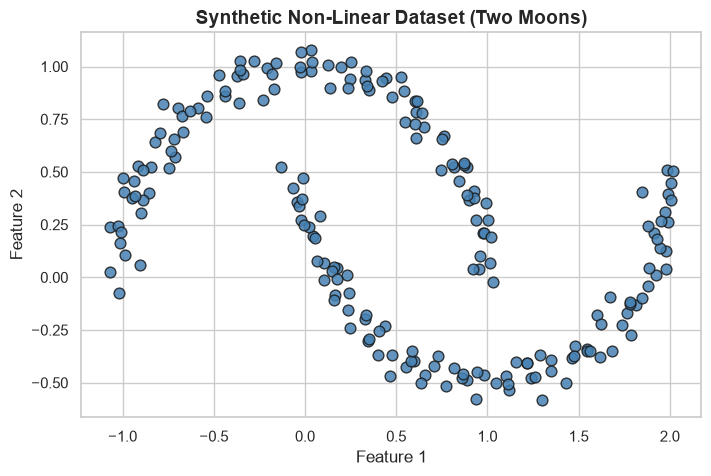

In [3]:
# Create a scatter plot of the raw data
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], s=60, color='steelblue', edgecolors='k', alpha=0.85)
plt.title('Synthetic Non-Linear Dataset (Two Moons)', fontsize=14, fontweight='bold')
plt.xlabel('Feature 1', fontsize=12)
plt.ylabel('Feature 2', fontsize=12)
plt.show()


**Visual Inspection:**  
The scatterplot clearly displays two distinct crescent-shaped clusters wrapping around each other. Because the boundary between them is non-linear, standard distance-to-centroid partitioning methods struggle to separate them accurately.


## Step 2 - Clustering with K-Means
We apply K-Means with $k = 2$ to evaluate how centroid-based clustering handles this non-linear structure.


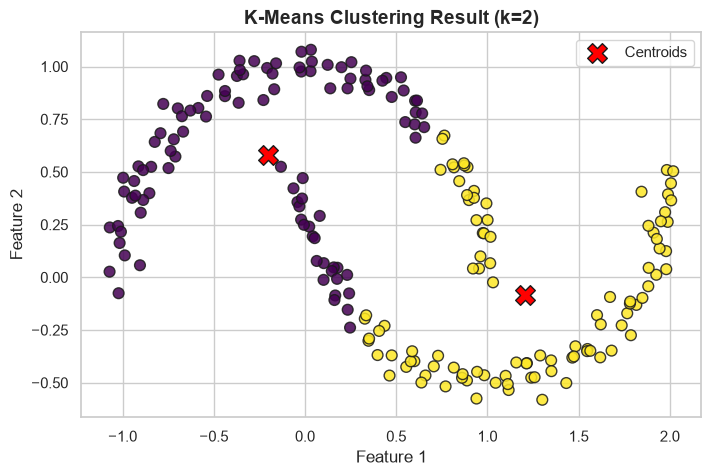

In [4]:
# Construct KMeans model
kmeans = KMeans(n_clusters=2, random_state=0, n_init=10)
cluster_km = kmeans.fit_predict(X)

# Plot KMeans clustering result
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=cluster_km, s=60, cmap='viridis', edgecolors='k', alpha=0.85)

# Overlay centroids
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X', edgecolors='k', label='Centroids')

plt.title('K-Means Clustering Result (k=2)', fontsize=14, fontweight='bold')
plt.xlabel('Feature 1', fontsize=12)
plt.ylabel('Feature 2', fontsize=12)
plt.legend()
plt.show()


### Observation on K-Means
As observed above, K-Means fails to correctly separate the two half-moon shapes.  
Because K-Means optimizes for minimum Euclidean distance to cluster centers, it inherently constructs linear Voronoi cell boundaries (hyperplanes). Consequently, it cuts vertically across both moons, incorrectly grouping parts of the upper and lower crescents together.


In [5]:
# Evaluate K-Means using Silhouette Score
km_sil = silhouette_score(X, cluster_km)
print(f"K-Means Silhouette Score: {km_sil:.4f}")


K-Means Silhouette Score: 0.4922


The Silhouette Score of approximately **0.492** indicates that points are moderately close to their assigned cluster centers relative to neighboring clusters. However, visual inspection proves that the clustering is fundamentally incorrect with respect to the true manifold structure.


## Step 3 - Clustering with DBSCAN
To handle non-linear arbitrary geometries, we employ **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)**.  
DBSCAN groups points based on local point density rather than distance to a central centroid:
- **Core Point:** A point having at least `min_samples` within distance $\epsilon$ (`eps`).
- **Border Point:** A point within distance $\epsilon$ of a core point, but with fewer than `min_samples` neighbors.
- **Noise Point:** A point that is neither a core point nor a border point (assigned label `-1`).

*Note:* DBSCAN is highly sensitive to the `eps` (radius) and `min_samples` parameters!


In [6]:
# Construct DBSCAN model
dbscan = DBSCAN(eps=0.3, min_samples=2)
cluster_db = dbscan.fit_predict(X)

# Check unique clusters and noise count
unique_labels = np.unique(cluster_db)
n_clusters_ = len(unique_labels[unique_labels != -1])
n_noise_ = np.sum(cluster_db == -1)

print(f"Identified Clusters: {n_clusters_}")
print(f"Identified Noise Points: {n_noise_} ({n_noise_ / len(X) * 100:.1f}%)")


Identified Clusters: 2
Identified Noise Points: 0 (0.0%)


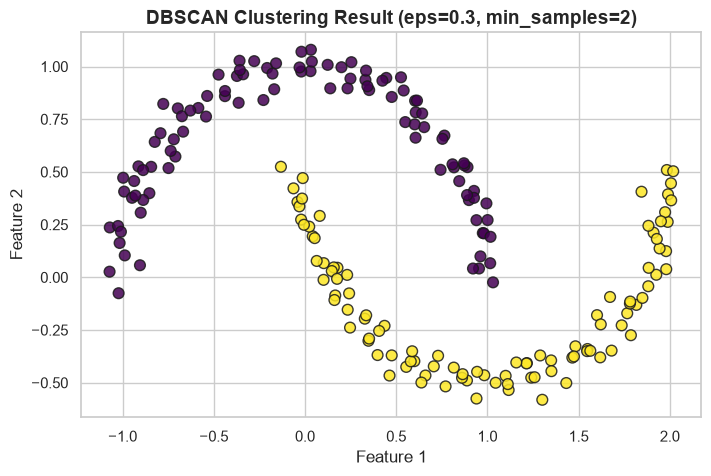

In [7]:
# Plot DBSCAN clustering results
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=cluster_db, s=60, cmap='viridis', edgecolors='k', alpha=0.85)
plt.title('DBSCAN Clustering Result (eps=0.3, min_samples=2)', fontsize=14, fontweight='bold')
plt.xlabel('Feature 1', fontsize=12)
plt.ylabel('Feature 2', fontsize=12)
plt.show()


### Observation on DBSCAN
DBSCAN successfully identifies the two non-linear crescent structures cleanly without misassigning any data points!  
Because density connectivity allows clusters to snake along arbitrary curves and contours, DBSCAN effortlessly follows the geometry of the data.


In [8]:
# Evaluate DBSCAN with Silhouette Score
db_sil = silhouette_score(X, cluster_db)
print(f"DBSCAN Silhouette Score: {db_sil:.4f}")


DBSCAN Silhouette Score: 0.3259


### The Silhouette Score Paradox on Non-Linear Geometries
Notice that DBSCAN achieves a Silhouette Score of **0.3259**, which is **substantially lower** than K-Means' score of **0.4922**, despite DBSCAN being visually and topologically superior!

**Why does this happen?**
1. **Geometric Assumption of Silhouette Coefficient:**  
   The Silhouette Coefficient is defined as:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   where $a(i)$ is the mean intra-cluster distance and $b(i)$ is the mean nearest-cluster distance. Both rely directly on **Euclidean distance**.
2. **Curved Shapes Penalize Silhouette Metric:**  
   In a crescent or spiral shape, two points belonging to opposite ends of the *same* cluster can have a large straight-line Euclidean distance between them ($a(i)$ is large). Simultaneously, a point at the tip of the upper moon may be physically very close in Euclidean space to the other moon ($b(i)$ is small).
3. **Conclusion:** The Silhouette Coefficient inherently favors convex, spherical, linearly separable clusters. For arbitrary manifold geometries, it cannot provide a reliable ground-truth assessment.


## Step 4 - Alternative Evaluation Methods for Non-Linear Clustering
When clustering non-linear distributions, reliable assessment requires:
1. **Percentage of Noisy Data:** Quantifies outliers flagged as `-1`.
2. **Visual Inspection:** Directly verifies topological conformity in 2D/3D projections.
3. **Davies-Bouldin Index (DBI):** Evaluates cluster separation and compactness. Lower values indicate better separation (range: $[0, \infty)$):
   $$R_{ij} = \frac{s_i + s_j}{d(\mu_i, \mu_j)}, \quad \text{DBI} = \frac{1}{k}\sum_{i=1}^k \max_{j \neq i} R_{ij}$$


In [9]:
# Compute Davies-Bouldin Index for DBSCAN and K-Means
db_dbi = davies_bouldin_score(X, cluster_db)
km_dbi = davies_bouldin_score(X, cluster_km)

print(f"DBSCAN Davies-Bouldin Index: {db_dbi:.4f}")
print(f"K-Means Davies-Bouldin Index: {km_dbi:.4f}")


DBSCAN Davies-Bouldin Index: 1.1623
K-Means Davies-Bouldin Index: 0.7701


## Step 5 - Sensitivity to DBSCAN Hyperparameters ($\epsilon$ and `min_samples`)
To demonstrate how sensitive DBSCAN is to its hyperparameters, we explore different combinations of `eps` and `min_samples`.


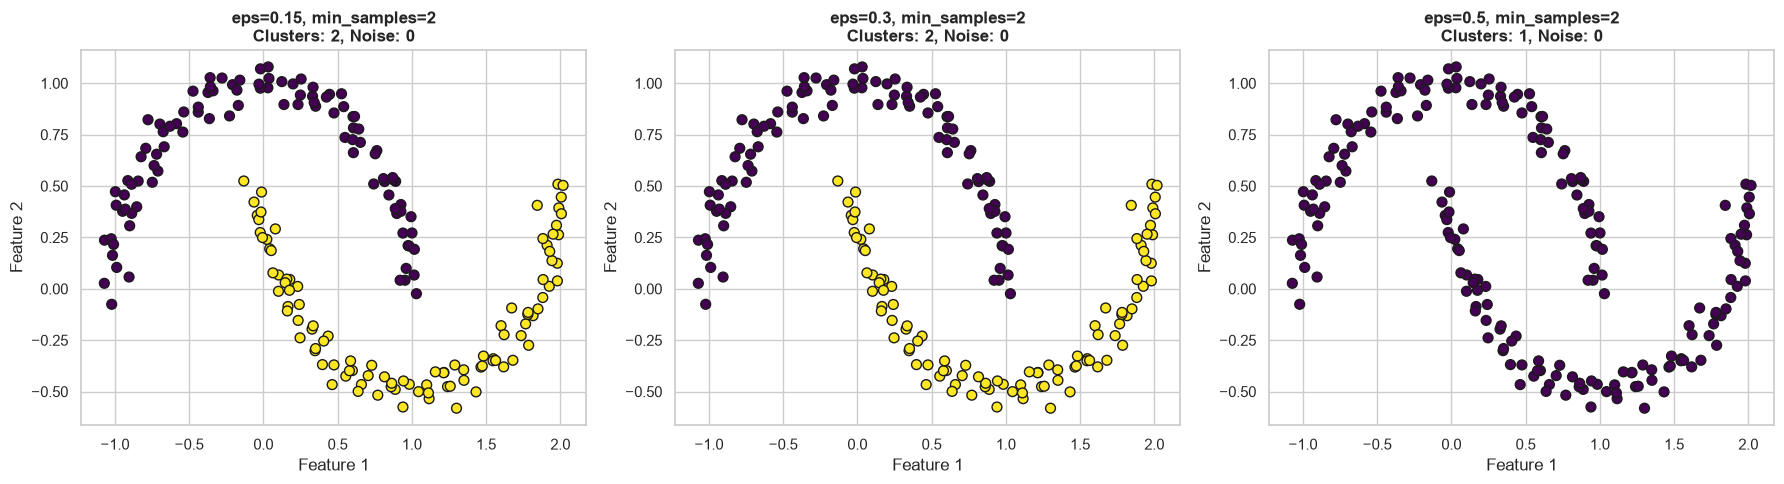

In [10]:
eps_values = [0.15, 0.30, 0.50]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, eps in enumerate(eps_values):
    db_exp = DBSCAN(eps=eps, min_samples=2)
    labels = db_exp.fit_predict(X)
    n_c = len(set(labels)) - (1 if -1 in labels else 0)
    n_n = list(labels).count(-1)
    
    axes[idx].scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50, edgecolors='k')
    axes[idx].set_title(f"eps={eps}, min_samples=2\nClusters: {n_c}, Noise: {n_n}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Feature 1')
    axes[idx].set_ylabel('Feature 2')

plt.tight_layout()
plt.show()


### Analysis of Hyperparameter Behavior:
- **`eps = 0.15` (Too Small):** The neighborhood radius is too restrictive, causing the moons to fragment into multiple smaller clusters and misclassifying sparser points as noise.
- **`eps = 0.30` (Optimal):** Accurately captures both moons as 2 continuous density-connected components with 0 noise points.
- **`eps = 0.50` (Too Large):** The neighborhood radius bridges the gap between the two moons, erroneously merging them into a single monolithic cluster.


## Step 6 - Comparative Summary: K-Means vs DBSCAN

| Property | K-Means | DBSCAN |
| :--- | :--- | :--- |
| **Cluster Shape Assumption** | Spherical / Convex | Arbitrary (Linear & Non-linear) |
| **Outlier / Noise Handling** | Highly sensitive (forces all points into clusters) | Robust (explicit noise classification `-1`) |
| **Parameters Required** | Number of clusters ($k$) | Radius ($\epsilon$) and density threshold (`min_samples`) |
| **Distance Metric Dependency** | Euclidean distance to centroid | Density-connectivity within $\epsilon$-neighborhood |
| **Suitable Evaluation Metric** | SSE / Inertia, Silhouette Coefficient | Visual inspection, Noise ratio, Adjusted Rand Index (when labels exist) |
